In [1]:
%pip install seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score,
    confusion_matrix
)

In [3]:
train = pd.read_csv("train_clean.csv")
test = pd.read_csv("test_clean.csv")

print("Training data:", train.shape)
print("Testing data:", test.shape)

Training data: (107740, 43)
Testing data: (82332, 43)


In [4]:
# Use a random sample to reduce memory usage
train = train.sample(
    n=min(30000, len(train)),
    random_state=42
).copy()

# Select the binary target
y_train = train["label"]
y_test = test["label"]

# Remove identifiers and target columns
drop_cols = ["label", "attack_cat"]

X_train = train.drop(columns=drop_cols)
X_test = test.drop(columns=drop_cols)

# Replace infinite values
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

print("Sampled training data:", X_train.shape)

Sampled training data: (30000, 41)


In [5]:
# Identify numeric and categorical features
num_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

cat_cols = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

# Preprocess numeric data
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical data
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
], sparse_threshold=1.0)

# Use fewer trees and limit tree depth
model = Pipeline([
    ("prep", preprocessor),
    ("rf", RandomForestClassifier(
        n_estimators=50,
        max_depth=16,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=1,
        class_weight="balanced"
    ))
])

print("Model created successfully.")

Model created successfully.


In [6]:
print("Training model...")

model.fit(X_train, y_train)

print("Training complete.")

predictions = model.predict(X_test)

print("\nAccuracy:",
      round(accuracy_score(y_test, predictions), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Normal", "Attack"],
    zero_division=0
))

Training model...
Training complete.

Accuracy: 0.8694

Classification report:
              precision    recall  f1-score   support

      Normal       0.98      0.73      0.83     37000
      Attack       0.82      0.99      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.90      0.86      0.86     82332
weighted avg       0.89      0.87      0.87     82332



In [7]:
# Predict the test set
y_pred = model.predict(X_test)

# Probability of the attack class (label = 1)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Attack"],
    zero_division=0
))

Accuracy: 0.8694
Precision: 0.8157
Recall: 0.9854
F1-score: 0.8926
ROC-AUC: 0.982

Detailed Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      0.73      0.83     37000
      Attack       0.82      0.99      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.90      0.86      0.86     82332
weighted avg       0.89      0.87      0.87     82332



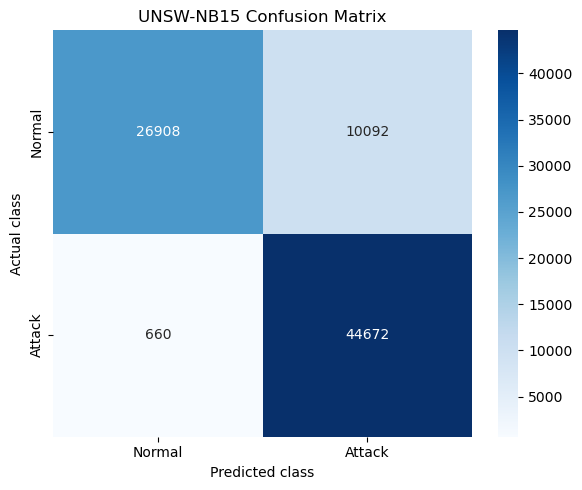

True negatives: 26908
False positives: 10092
False negatives: 660
True positives: 44672
False positive rate: 0.2728
False negative rate: 0.0146


In [8]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"]
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("UNSW-NB15 Confusion Matrix")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

print("False positive rate:",
      round(fp / (fp + tn), 4) if fp + tn else 0)

print("False negative rate:",
      round(fn / (fn + tp), 4) if fn + tp else 0)

In [9]:
# Copy the original test data for analysis
errors = test.loc[X_test.index].copy()

errors["actual_label"] = y_test
errors["predicted_label"] = y_pred
errors["attack_probability"] = y_prob

# Keep only incorrect predictions
errors = errors[
    errors["actual_label"] != errors["predicted_label"]
].copy()

# Categorize the errors
errors["error_type"] = np.where(
    (errors["actual_label"] == 1) &
    (errors["predicted_label"] == 0),
    "False Negative",
    "False Positive"
)

print("Total incorrect predictions:", len(errors))
print("\nErrors by type:")
print(errors["error_type"].value_counts())

# Display a selection of errors
columns_to_show = [
    "error_type",
    "actual_label",
    "predicted_label",
    "attack_probability",
    "attack_cat",
    "proto",
    "service",
    "state",
    "dur",
    "sbytes",
    "dbytes"
]

print("\nExample misclassified records:")
print(errors[columns_to_show].head(15).to_string(index=False))

# Save all errors for further investigation
errors.to_csv("misclassified_records.csv", index=False)
print("\nSaved: misclassified_records.csv")

Total incorrect predictions: 10752

Errors by type:
error_type
False Positive    10092
False Negative      660
Name: count, dtype: int64

Example misclassified records:
    error_type  actual_label  predicted_label  attack_probability attack_cat proto service state      dur  sbytes  dbytes
False Positive             0                1            0.869895     Normal   udp       -   INT 0.000011     496       0
False Positive             0                1            0.826333     Normal   udp       -   INT 0.000008    1762       0
False Positive             0                1            0.738819     Normal   udp       -   INT 0.000005    1068       0
False Positive             0                1            0.675426     Normal   udp       -   INT 0.000006     900       0
False Positive             0                1            0.767764     Normal   udp       -   INT 0.000010    2126       0
False Positive             0                1            0.852866     Normal   udp       -   INT 0.

Top 15 important features:
          feature  importance
        num__sttl    0.137126
num__ct_state_ttl    0.124681
       num__dload    0.090893
       num__dmean    0.058660
      num__ackdat    0.051034
        num__dttl    0.043256
       num__dpkts    0.041572
  num__ct_srv_dst    0.040286
   cat__state_INT    0.036152
      num__tcprtt    0.029108
      num__sinpkt    0.025594
      num__synack    0.024892
        num__rate    0.024475
      num__sbytes    0.022940
      num__dbytes    0.022489


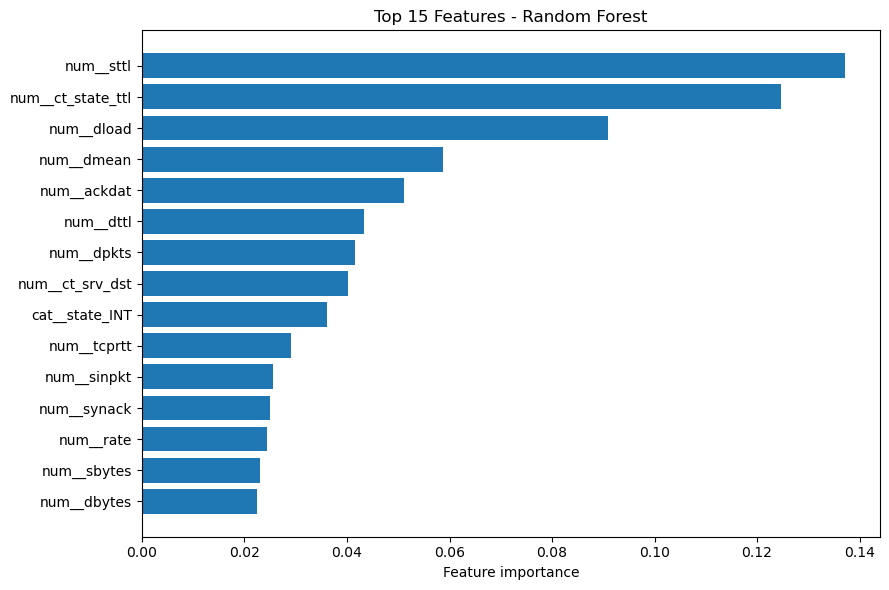

In [10]:
# Get feature names after preprocessing
feature_names = (
    model.named_steps["prep"].get_feature_names_out()
)

# Get Random Forest feature importance scores
importances = model.named_steps["rf"].feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
)

print("Top 15 important features:")
print(importance_df.head(15).to_string(index=False))

# Plot the top 15
top_features = importance_df.head(15).sort_values("importance")

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["feature"],
    top_features["importance"]
)
plt.xlabel("Feature importance")
plt.title("Top 15 Features - Random Forest")
plt.tight_layout()
plt.show()

In [11]:
# Combine actual labels, predictions, and attack categories
analysis_df = pd.DataFrame({
    "actual": np.asarray(y_test),
    "predicted": np.asarray(y_pred),
    "attack_cat": test.loc[X_test.index, "attack_cat"].to_numpy()
})

# Analyse actual attack records only
attacks = analysis_df[analysis_df["actual"] == 1].copy()

attacks["detected"] = (
    attacks["predicted"] == 1
).astype(int)

category_results = attacks.groupby("attack_cat").agg(
    total_records=("detected", "size"),
    detected=("detected", "sum"),
    detection_rate=("detected", "mean")
).sort_values("detection_rate")

category_results["detection_rate"] = (
    category_results["detection_rate"] * 100
).round(2)

print(category_results)

                total_records  detected  detection_rate
attack_cat                                             
Fuzzers                  6062      5451           89.92
Shellcode                 378       375           99.21
Exploits                11132     11093           99.65
Analysis                  677       676           99.85
Reconnaissance           3496      3492           99.89
DoS                      4089      4087           99.95
Backdoor                  583       583          100.00
Generic                 18871     18871          100.00
Worms                      44        44          100.00


The core algorithim in this model is Random Forest Classifier. It builds decision trees, where each tree learns rules from the training data. The trees then vote, and the forest combines their predictions into a final classification. The model also provides an estimated probability for the attack class.

This code investigates model error by identifing incorrectly classified records and labels each error as either a false positive or false negative. It also records the model's estimated attack probability and selected network attributes.